# SugarSense: Early Diabetes Risk Screening

## Phase 1: Data Understanding and Preprocessing

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("diabetes_screening_data.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df.shape

(768, 9)

In [ ]:
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
df.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

zero_counts = (df[zero_columns] == 0).sum()

zero_counts

,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


In [ ]:
zero_percent = (df[zero_columns] == 0).mean() * 100

zero_percent

,0
Glucose,0.651042
BloodPressure,4.557292
SkinThickness,29.557292
Insulin,48.697917
BMI,1.432292


In [ ]:
problematic_values = pd.DataFrame({
    "Count": zero_counts,
    "Percentage": zero_percent
})

problematic_values

,Count,Percentage
Glucose,5,0.651042
BloodPressure,35,4.557292
SkinThickness,227,29.557292
Insulin,374,48.697917
BMI,11,1.432292


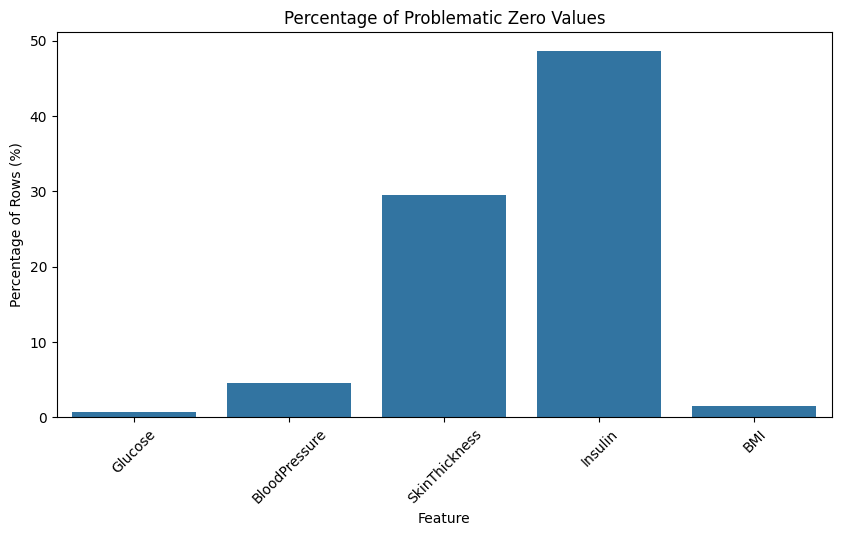

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=problematic_values.index,
    y=problematic_values["Percentage"]
)

plt.title("Percentage of Problematic Zero Values")
plt.xlabel("Feature")
plt.ylabel("Percentage of Rows (%)")
plt.xticks(rotation=45)

plt.show()

### Hidden Missing Values

Although the dataset contains no explicit NaN values, several clinical
measurements contain zero values that are physiologically implausible.
For example, glucose, blood pressure and BMI cannot realistically be zero
for a living patient. These zero values are therefore treated as missing
measurements rather than genuine observations. The problematic values
will be converted to NaN and imputed inside the model pipeline after the
train-test split to avoid data leakage.

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[df.duplicated()]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome


In [ ]:
df["Outcome"].value_counts()

,count
Outcome,
0,500
1,268


In [ ]:
df["Outcome"].value_counts(normalize=True) * 100

,proportion
Outcome,
0,65.104167
1,34.895833


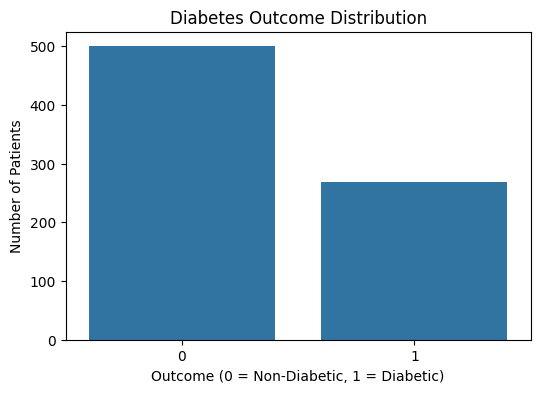

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Outcome")

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = Non-Diabetic, 1 = Diabetic)")
plt.ylabel("Number of Patients")

plt.show()

In [ ]:
class_balance = pd.DataFrame({
    "Count": df["Outcome"].value_counts().sort_index(),
    "Percentage": df["Outcome"].value_counts(normalize=True).sort_index() * 100
})

class_balance

,Count,Percentage
Outcome,,
0,500,65.104167
1,268,34.895833


In [ ]:
class_balance.index = ["Non-Diabetic (0)", "Diabetic (1)"]

class_balance

,Count,Percentage
Non-Diabetic (0),500,65.104167
Diabetic (1),268,34.895833


### Class Balance

The target variable is moderately imbalanced, with fewer diabetic patients
than non-diabetic patients. Therefore, accuracy alone may be misleading.
Recall, precision, F1-score and ROC-AUC will also be considered when
evaluating the classification models.

## Phase 2: Exploratory Data Analysis

In [ ]:
features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

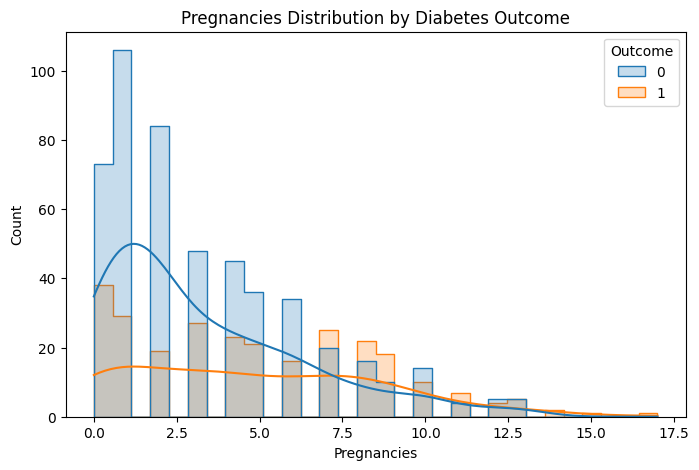

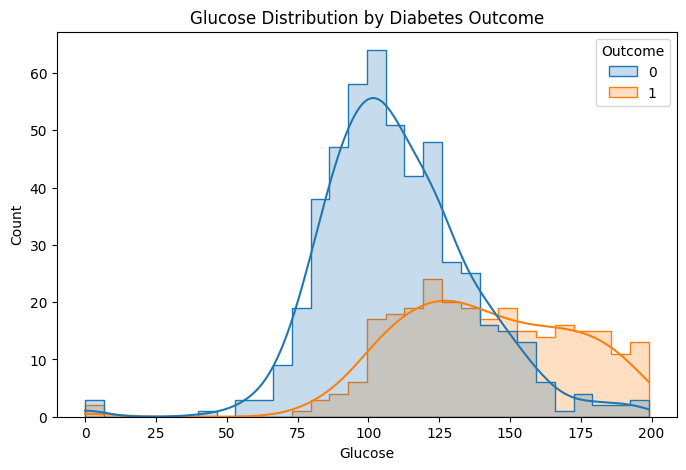

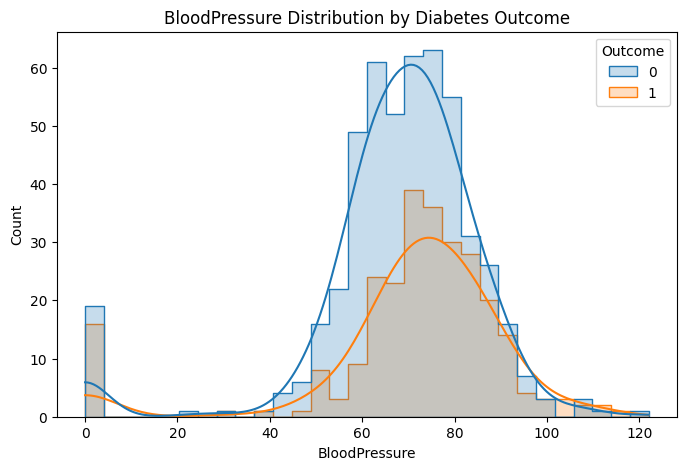

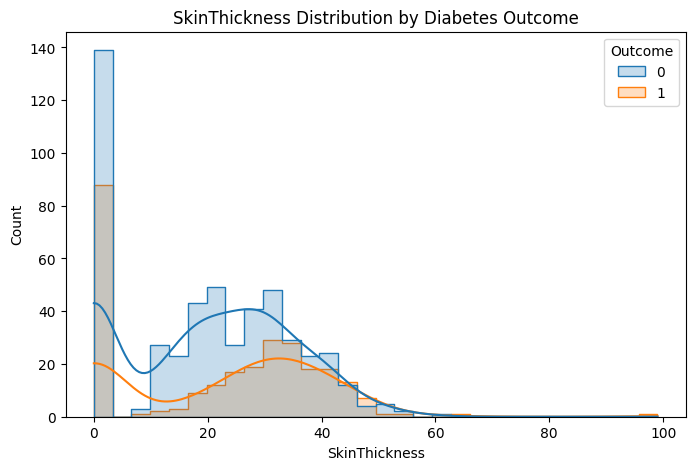

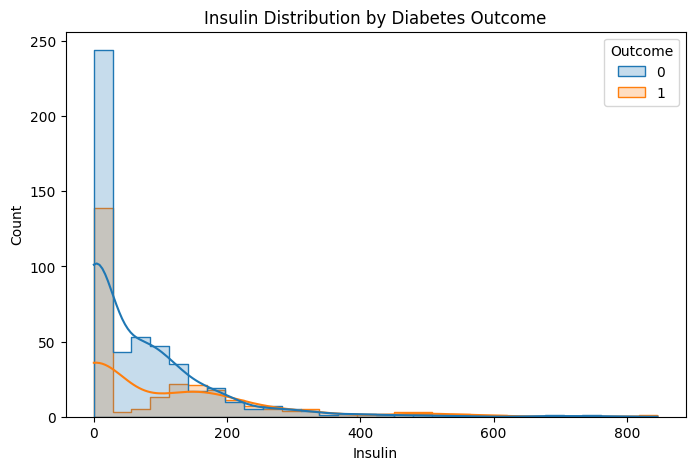

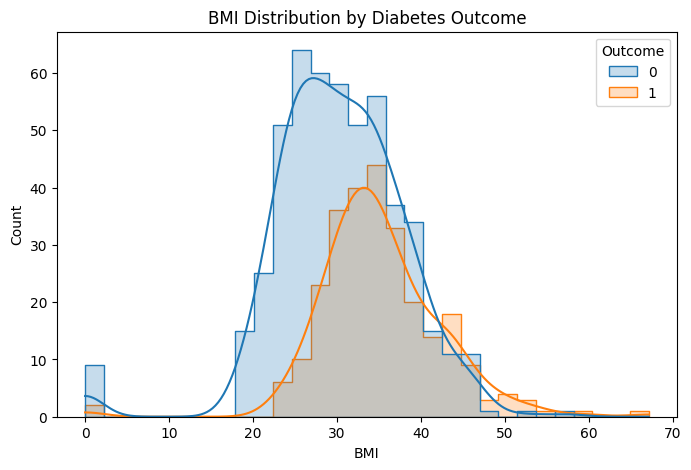

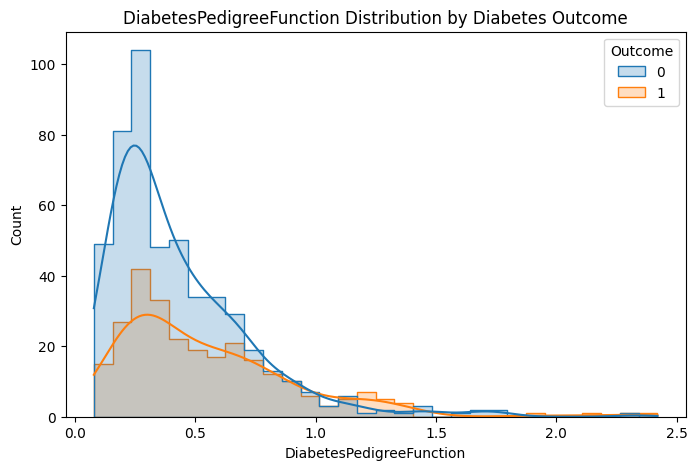

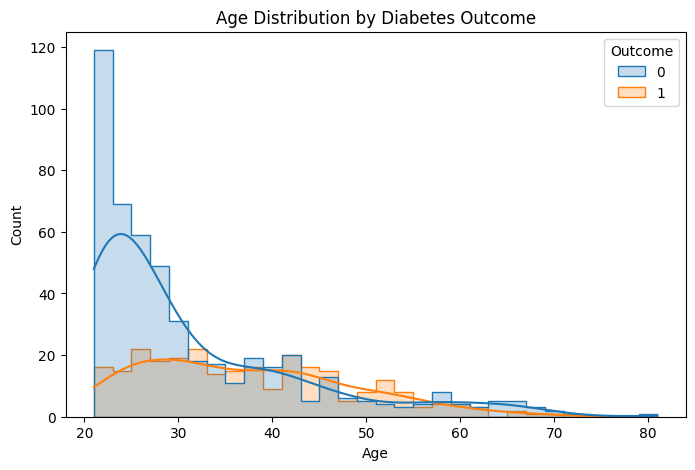

In [ ]:
for feature in features:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=feature,
        hue="Outcome",
        kde=True,
        bins=30,
        element="step"
    )

    plt.title(f"{feature} Distribution by Diabetes Outcome")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.show()

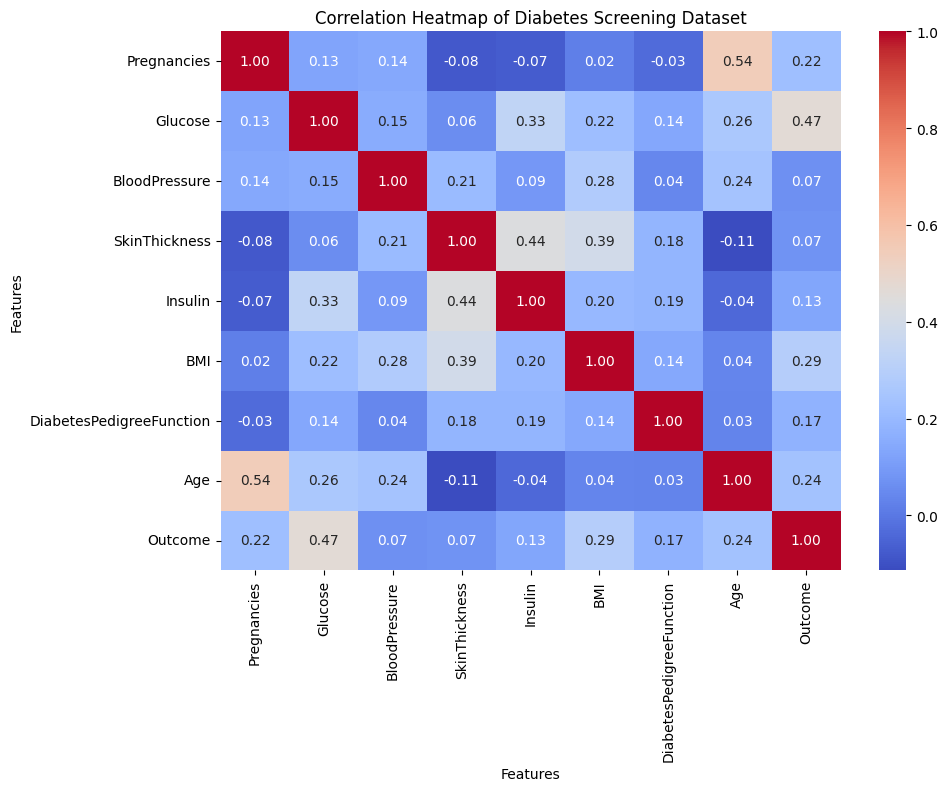

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Diabetes Screening Dataset")
plt.xlabel("Features")
plt.ylabel("Features")

plt.show()

In [ ]:
correlations = (
    df.corr()["Outcome"]
    .drop("Outcome")
    .sort_values(key=abs, ascending=False)
)

correlations

,Outcome
Glucose,0.466581
BMI,0.292695
Age,0.238356
Pregnancies,0.221898
DiabetesPedigreeFunction,0.173844
Insulin,0.130548
SkinThickness,0.074752
BloodPressure,0.065068


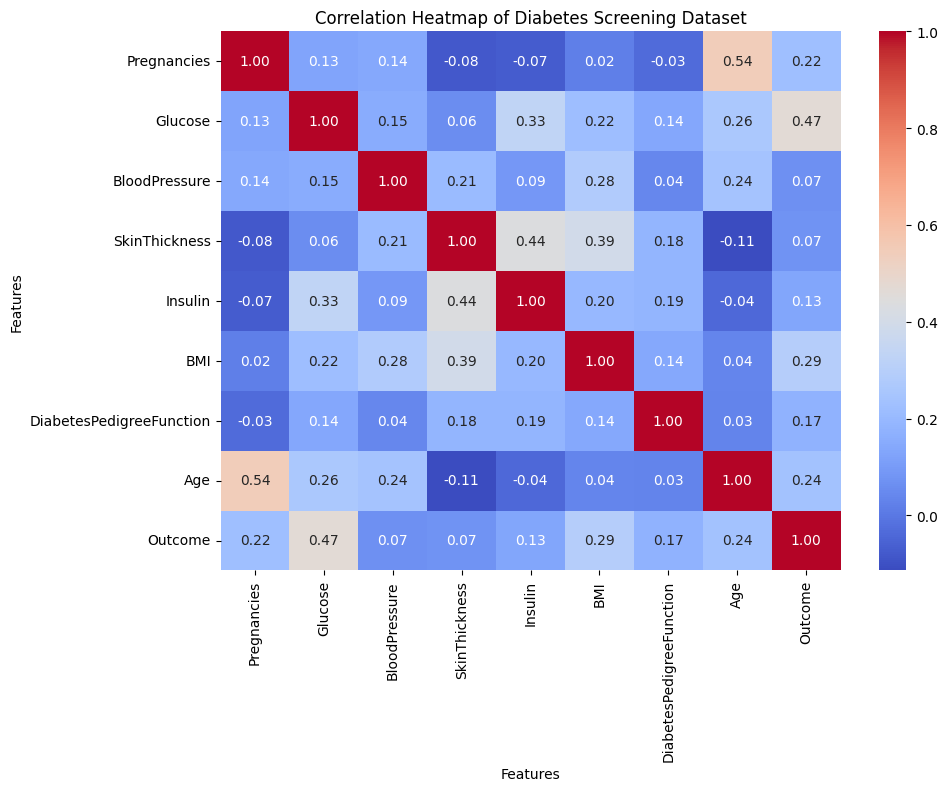

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Diabetes Screening Dataset")
plt.xlabel("Features")
plt.ylabel("Features")

plt.show()

In [ ]:
correlations = (
    df.corr()["Outcome"]
    .drop("Outcome")
    .sort_values(key=abs, ascending=False)
)

correlations

,Outcome
Glucose,0.466581
BMI,0.292695
Age,0.238356
Pregnancies,0.221898
DiabetesPedigreeFunction,0.173844
Insulin,0.130548
SkinThickness,0.074752
BloodPressure,0.065068


### EDA Observations

1. Glucose has the strongest positive correlation with the diabetes outcome (0.47), indicating that higher glucose levels are associated with a higher likelihood of diabetes.

2. BMI shows the second strongest correlation with the outcome (0.29), suggesting that higher BMI is associated with increased diabetes risk.

3. Age and Pregnancies also show positive relationships with the outcome, although their correlations are weaker than Glucose and BMI.

4. DiabetesPedigreeFunction has a relatively weak positive correlation with the outcome, while Insulin, SkinThickness, and BloodPressure show very weak linear correlations.

5. The relatively weak correlations of some features do not necessarily mean they are useless for prediction because machine-learning models can capture nonlinear relationships and interactions between features.

## Phase 3: Feature Engineering

In [ ]:
df["Obesity_Flag"] = (df["BMI"] >= 30).astype(int)

In [ ]:
df["High_Glucose_Flag"] = (df["Glucose"] >= 126).astype(int)

In [ ]:
df["Age_BMI_Interaction"] = df["Age"] * df["BMI"]

In [ ]:
df[[
    "BMI",
    "Obesity_Flag",
    "Glucose",
    "High_Glucose_Flag",
    "Age",
    "Age_BMI_Interaction"
]].head()

,BMI,Obesity_Flag,Glucose,High_Glucose_Flag,Age,Age_BMI_Interaction
0,33.6,1,148,1,50,1680.0
1,26.6,0,85,0,31,824.6
2,23.3,0,183,1,32,745.6
3,28.1,0,89,0,21,590.1
4,43.1,1,137,1,33,1422.3


### Feature Engineering

Three new features were created using only information from the same patient record.

- `Obesity_Flag`: Indicates whether BMI is at least 30, providing a simple obesity-related risk indicator.
- `High_Glucose_Flag`: Indicates whether the glucose measurement is at least 126, providing an elevated-glucose indicator.
- `Age_BMI_Interaction`: Multiplies age and BMI to capture a possible combined effect of these two risk factors.

These features are row-level transformations and do not use information calculated from the entire dataset.

## Phase 4: Train-Test Split and Model Preparation

In [ ]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 11)
y shape: (768,)


In [ ]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[zero_columns] = X[zero_columns].replace(0, np.nan)

In [ ]:
X.isna().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Obesity_Flag,0
High_Glucose_Flag,0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (614, 11)
Test set: (154, 11)

Training target distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Test target distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        random_state=42,
        max_iter=1000
    ))
])

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ))
])

In [ ]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

In [ ]:
models = {
    "Logistic Regression": logistic_pipeline,
    "KNN": knn_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline,
    "XGBoost": xgb_pipeline,
    "SVM": svm_pipeline}

## Phase 5: Baseline Model Comparison

### 5.1 Stratified Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [ ]:
results = []

for name, model in models.items():

    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy": cv_results["test_accuracy"].mean(),
        "Precision": cv_results["test_precision"].mean(),
        "Recall": cv_results["test_recall"].mean(),
        "F1": cv_results["test_f1"].mean(),
        "ROC-AUC": cv_results["test_roc_auc"].mean(),
        "Train ROC-AUC": cv_results["train_roc_auc"].mean()
    })

In [ ]:
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train ROC-AUC
0,Logistic Regression,0.770319,0.653555,0.733666,0.690061,0.839459,0.855492
1,KNN,0.768666,0.688594,0.635548,0.657507,0.815994,0.907789
2,Decision Tree,0.695415,0.562807,0.569989,0.566054,0.666244,1.000000
3,Random Forest,0.773584,0.713885,0.598007,0.648544,0.822542,1.000000
4,XGBoost,0.741024,0.648499,0.584385,0.610560,0.791645,1.000000
5,SVM,0.765427,0.647156,0.747841,0.689891,0.838639,0.912574


In [ ]:
results = []

for name, model in models.items():

    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    results.append({
        "Model": name,

        "Accuracy Mean": cv_results["test_accuracy"].mean(),
        "Accuracy Std": cv_results["test_accuracy"].std(),

        "Precision Mean": cv_results["test_precision"].mean(),
        "Precision Std": cv_results["test_precision"].std(),

        "Recall Mean": cv_results["test_recall"].mean(),
        "Recall Std": cv_results["test_recall"].std(),

        "F1 Mean": cv_results["test_f1"].mean(),
        "F1 Std": cv_results["test_f1"].std(),

        "ROC-AUC Mean": cv_results["test_roc_auc"].mean(),
        "ROC-AUC Std": cv_results["test_roc_auc"].std(),

        "Train ROC-AUC": cv_results["train_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,Train ROC-AUC
0,Logistic Regression,0.770319,0.013737,0.653555,0.029771,0.733666,0.034565,0.690061,0.012986,0.839459,0.017579,0.855492
1,KNN,0.768666,0.024048,0.688594,0.065618,0.635548,0.037316,0.657507,0.019036,0.815994,0.039716,0.907789
2,Decision Tree,0.695415,0.031760,0.562807,0.046903,0.569989,0.046403,0.566054,0.044209,0.666244,0.034310,1.000000
3,Random Forest,0.773584,0.028613,0.713885,0.072122,0.598007,0.038400,0.648544,0.037403,0.822542,0.035707,1.000000
4,XGBoost,0.741024,0.028975,0.648499,0.059445,0.584385,0.063179,0.610560,0.040042,0.791645,0.037583,1.000000
5,SVM,0.765427,0.030966,0.647156,0.059443,0.747841,0.067454,0.689891,0.032000,0.838639,0.023873,0.912574


In [ ]:
results_df["Overfit Gap"] = (
    results_df["Train ROC-AUC"] -
    results_df["ROC-AUC Mean"]
)

results_df

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std,Train ROC-AUC,Overfit Gap
0,Logistic Regression,0.770319,0.013737,0.653555,0.029771,0.733666,0.034565,0.690061,0.012986,0.839459,0.017579,0.855492,0.016033
1,KNN,0.768666,0.024048,0.688594,0.065618,0.635548,0.037316,0.657507,0.019036,0.815994,0.039716,0.907789,0.091795
2,Decision Tree,0.695415,0.031760,0.562807,0.046903,0.569989,0.046403,0.566054,0.044209,0.666244,0.034310,1.000000,0.333756
3,Random Forest,0.773584,0.028613,0.713885,0.072122,0.598007,0.038400,0.648544,0.037403,0.822542,0.035707,1.000000,0.177458
4,XGBoost,0.741024,0.028975,0.648499,0.059445,0.584385,0.063179,0.610560,0.040042,0.791645,0.037583,1.000000,0.208355
5,SVM,0.765427,0.030966,0.647156,0.059443,0.747841,0.067454,0.689891,0.032000,0.838639,0.023873,0.912574,0.073934


### 5.2 Class Imbalance Handling

In [ ]:
scale_pos_weight = (
    y_train.value_counts()[0] /
    y_train.value_counts()[1]
)

scale_pos_weight

np.float64(1.8691588785046729)

In [ ]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight
    ))
])

In [ ]:
models = {
    "Logistic Regression": logistic_pipeline,
    "KNN": knn_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline,
    "XGBoost": xgb_pipeline,
    "SVM": svm_pipeline
}

## Phase 6: Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

### 6.1 RandomizedSearchCV

In [ ]:
logistic_param_dist = {
    "model__C": np.logspace(-3, 2, 20),
    "model__solver": ["liblinear", "lbfgs"]
}

logistic_search = RandomizedSearchCV(
    estimator=logistic_pipeline,
    param_distributions=logistic_param_dist,
    n_iter=10,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

logistic_search.fit(X_train, y_train)

print("Best Parameters:", logistic_search.best_params_)
print("Best CV ROC-AUC:", logistic_search.best_score_)

Best Parameters: {'model__solver': 'liblinear', 'model__C': np.float64(0.12742749857031335)}
Best CV ROC-AUC: 0.841906146179402


In [ ]:
svm_param_dist = {
    "model__C": np.logspace(-2, 2, 20),
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto"]
}

svm_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=svm_param_dist,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

svm_search.fit(X_train, y_train)

print("Best Parameters:", svm_search.best_params_)
print("Best CV ROC-AUC:", svm_search.best_score_)

Best Parameters: {'model__kernel': 'rbf', 'model__gamma': 'scale', 'model__C': np.float64(0.7847599703514611)}
Best CV ROC-AUC: 0.8386531007751937


In [ ]:
xgb_param_dist = {
    "model__n_estimators": [100, 200, 300, 400],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

xgb_search.fit(X_train, y_train)

print("Best Parameters:", xgb_search.best_params_)
print("Best CV ROC-AUC:", xgb_search.best_score_)

Best Parameters: {'model__subsample': 0.9, 'model__n_estimators': 400, 'model__max_depth': 3, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.7}
Best CV ROC-AUC: 0.838452380952381


In [ ]:
tuning_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "XGBoost"
    ],
    "Before Tuning ROC-AUC": [
        results_df.loc[
            results_df["Model"] == "Logistic Regression",
            "ROC-AUC Mean"
        ].iloc[0],
        results_df.loc[
            results_df["Model"] == "SVM",
            "ROC-AUC Mean"
        ].iloc[0],
        results_df.loc[
            results_df["Model"] == "XGBoost",
            "ROC-AUC Mean"
        ].iloc[0]
    ],
    "After Tuning ROC-AUC": [
        logistic_search.best_score_,
        svm_search.best_score_,
        xgb_search.best_score_
    ]
})

tuning_results["Improvement"] = (
    tuning_results["After Tuning ROC-AUC"] -
    tuning_results["Before Tuning ROC-AUC"]
)

tuning_results

,Model,Before Tuning ROC-AUC,After Tuning ROC-AUC,Improvement
0,Logistic Regression,0.839459,0.841906,0.002447
1,SVM,0.838639,0.838653,0.000014
2,XGBoost,0.791645,0.838452,0.046808


In [ ]:
tuned_models = {
    "Logistic Regression": logistic_search.best_estimator_,
    "SVM": svm_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_
}

## Phase 7: Final Model Evaluation on the Unseen Test Set

### 7.1 Test Set Performance

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

test_results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_results_df = pd.DataFrame(test_results)

test_results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.733766,0.594203,0.759259,0.666667,0.813148
1,SVM,0.753247,0.621212,0.759259,0.683333,0.807407
2,XGBoost,0.753247,0.611111,0.814815,0.698413,0.819259


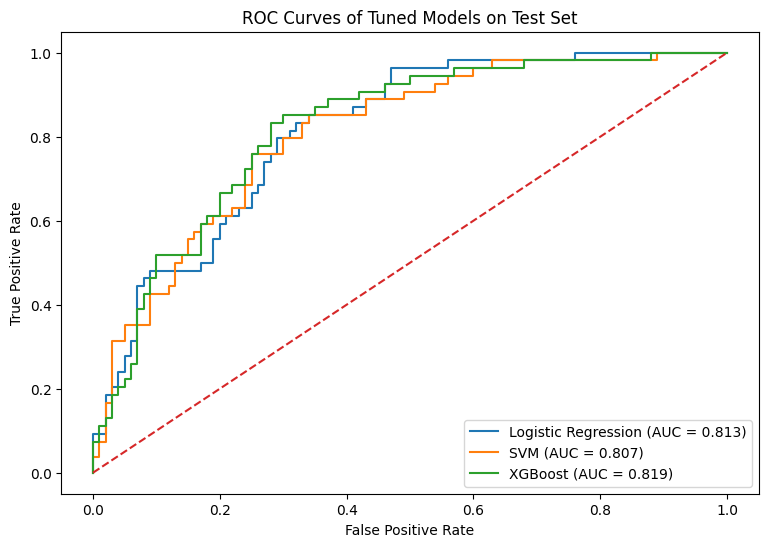

In [ ]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 6))

for name, model in tuned_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curves of Tuned Models on Test Set")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

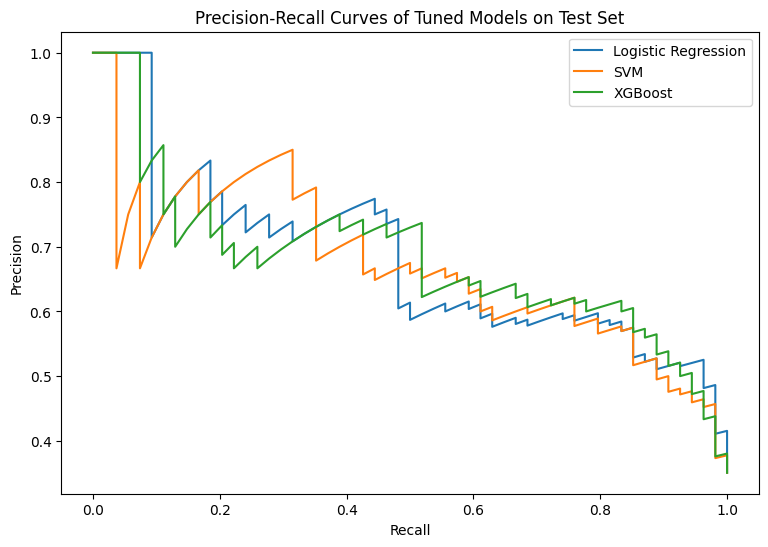

In [ ]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(9, 6))

for name, model in tuned_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test,
        y_prob
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.title("Precision-Recall Curves of Tuned Models on Test Set")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

In [ ]:
final_model_name = "Logistic Regression"
final_model = logistic_search.best_estimator_

print("Final Model:", final_model_name)

Final Model: Logistic Regression


### Final Model Selection

The final model was selected using cross-validation performance on the training data, without using the test set for model selection.

Logistic Regression achieved the highest mean cross-validated ROC-AUC among the tuned models. Therefore, it was selected as the final model for the remaining analysis.

The test set was kept completely separate until the final evaluation stage to avoid data leakage.

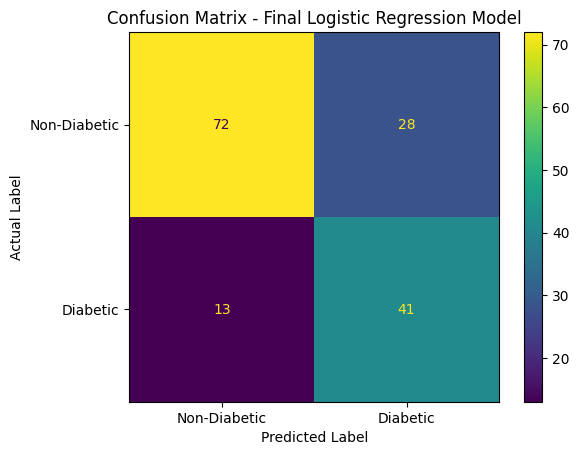

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_test_pred = final_model.predict(X_test)

cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot()

plt.title("Confusion Matrix - Final Logistic Regression Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### 7.2 Confusion Matrix

In [ ]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 72
False Positives: 28
False Negatives: 13
True Positives: 41


## Phase 8: Threshold Tuning for High Recall

In [ ]:
from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    final_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [ ]:
from sklearn.metrics import precision_score, recall_score

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.01):
    oof_predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_train,
        oof_predictions,
        zero_division=0
    )

    recall = recall_score(
        y_train,
        oof_predictions,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.head()

,Threshold,Precision,Recall
0,0.10,0.390511,1.0
1,0.11,0.395564,1.0
2,0.12,0.400749,1.0
3,0.13,0.406072,1.0
4,0.14,0.413127,1.0


In [ ]:
eligible_thresholds = threshold_df[
    threshold_df["Recall"] >= 0.85
]

best_threshold_row = eligible_thresholds.loc[
    eligible_thresholds["Precision"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Selected Threshold:", best_threshold)
print("OOF Precision:", best_threshold_row["Precision"])
print("OOF Recall:", best_threshold_row["Recall"])

Selected Threshold: 0.34999999999999987
OOF Precision: 0.5244956772334294
OOF Recall: 0.8504672897196262


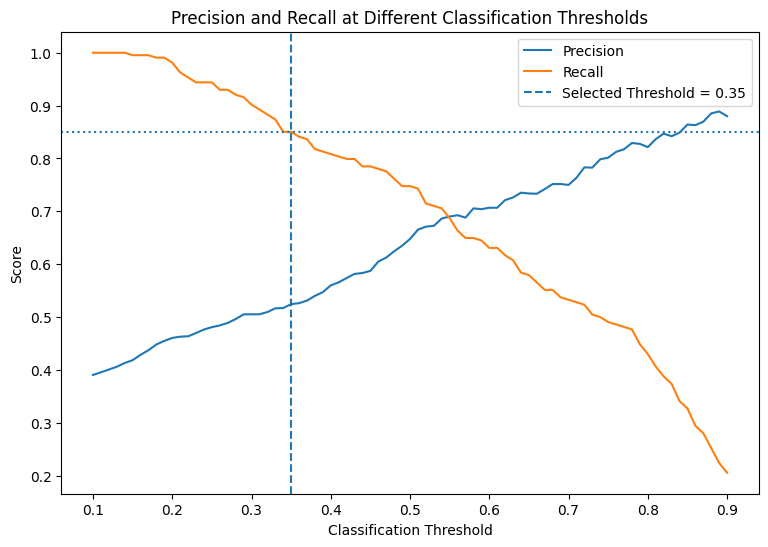

In [ ]:
plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected Threshold = {best_threshold:.2f}"
)

plt.axhline(
    0.85,
    linestyle=":"
)

plt.title("Precision and Recall at Different Classification Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.show()

In [ ]:
test_probabilities = final_model.predict_proba(X_test)[:, 1]

default_predictions = (
    test_probabilities >= 0.50
).astype(int)

tuned_predictions = (
    test_probabilities >= best_threshold
).astype(int)

threshold_comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1"
    ],
    "Default Threshold (0.50)": [
        precision_score(y_test, default_predictions),
        recall_score(y_test, default_predictions),
        f1_score(y_test, default_predictions)
    ],
    "Tuned Threshold": [
        precision_score(y_test, tuned_predictions),
        recall_score(y_test, tuned_predictions),
        f1_score(y_test, tuned_predictions)
    ]
})

threshold_comparison

,Metric,Default Threshold (0.50),Tuned Threshold
0,Precision,0.594203,0.534884
1,Recall,0.759259,0.851852
2,F1,0.666667,0.657143


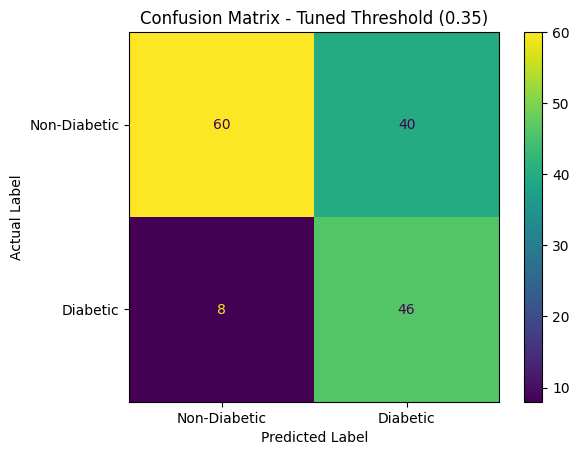

In [ ]:
cm_tuned = confusion_matrix(
    y_test,
    tuned_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot()

plt.title(
    f"Confusion Matrix - Tuned Threshold ({best_threshold:.2f})"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Threshold Tuning

The default classification threshold of 0.50 was adjusted because the primary objective of this screening task is to reduce false negatives.

The new threshold was selected using out-of-fold predictions from the training data only. The selected threshold achieved at least 85% recall while maximizing precision among the eligible thresholds.

When the threshold is lowered, the model becomes more likely to classify a patient as high-risk. This generally increases recall and reduces false negatives, but it can also increase false positives and reduce precision.

For a diabetes screening application, accepting some additional false positives may be preferable to missing diabetic patients who may require further medical evaluation.

In [ ]:
logistic_model = final_model.named_steps["model"]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
})

feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute Importance",
    ascending=False
)

feature_importance

,Feature,Coefficient,Absolute Importance
1,Glucose,1.062247,1.062247
5,BMI,0.410111,0.410111
0,Pregnancies,0.323214,0.323214
8,Obesity_Flag,0.260402,0.260402
6,DiabetesPedigreeFunction,0.256798,0.256798
7,Age,0.128650,0.128650
10,Age_BMI_Interaction,0.096020,0.096020
3,SkinThickness,0.029916,0.029916
2,BloodPressure,0.018189,0.018189
4,Insulin,-0.014586,0.014586


## Phase 9: Feature Importance and Final Conclusion

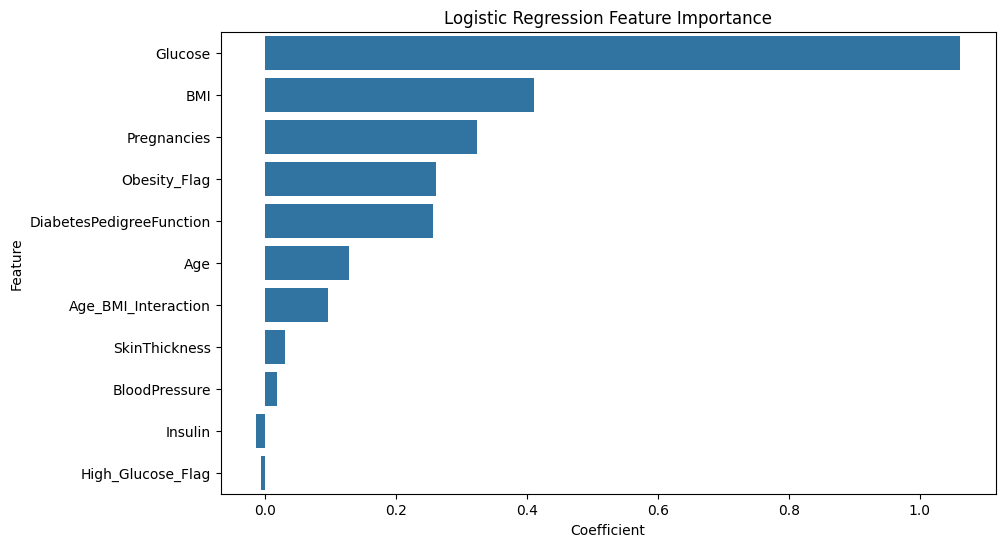

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Coefficient",
    y="Feature"
)

plt.title("Logistic Regression Feature Importance")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()

## Final Conclusion

The SugarSense model was developed to identify patients who may be at increased risk of diabetes using supervised machine learning.

Several clinical measurements showed useful relationships with the diabetes outcome, with Glucose showing the strongest individual relationship in the exploratory analysis. BMI, Age and Pregnancies also provided useful predictive information.

Six classification algorithms were initially compared using stratified 5-fold cross-validation. Logistic Regression and SVM achieved the strongest ROC-AUC performance, while the Decision Tree showed substantial overfitting.

Logistic Regression, SVM and XGBoost were subsequently tuned using RandomizedSearchCV with ROC-AUC as the optimization metric. Logistic Regression achieved the highest cross-validated ROC-AUC after tuning and was therefore selected as the final model without using the test set for model selection.

Because the application prioritizes identifying diabetic patients, threshold tuning was performed using out-of-fold predictions from the training data. A threshold achieving at least 85% recall was selected while maximizing precision among eligible thresholds.

The final model should be considered a screening aid rather than a diagnostic system. The Pima Indians Diabetes dataset represents a specific population and may not generalize to all populations, including different age groups, sexes, ethnicities or healthcare settings. Clinical validation and evaluation on more diverse datasets would be necessary before real-world medical use.

In [ ]:
import joblib

joblib.dump(
    {
        "model": final_model,
        "threshold": best_threshold
    },
    "sugarsense_model.joblib"
)

print("Model saved successfully.")

Model saved successfully.


In [ ]:
def screen_patient(patient_data):

    patient_df = pd.DataFrame([patient_data])

    patient_df["Obesity_Flag"] = (
        patient_df["BMI"] >= 30
    ).astype(int)

    patient_df["High_Glucose_Flag"] = (
        patient_df["Glucose"] >= 126
    ).astype(int)

    patient_df["Age_BMI_Interaction"] = (
        patient_df["Age"] * patient_df["BMI"]
    )

    patient_df[zero_columns] = patient_df[
        zero_columns
    ].replace(0, np.nan)

    probability = final_model.predict_proba(
        patient_df
    )[0, 1]

    prediction = int(
        probability >= best_threshold
    )

    return {
        "Diabetes_Risk_Probability": probability,
        "Prediction": prediction,
        "Result": (
            "Higher Risk - Further Screening Recommended"
            if prediction == 1
            else
            "Lower Risk - Continue Routine Screening"
        )
    }

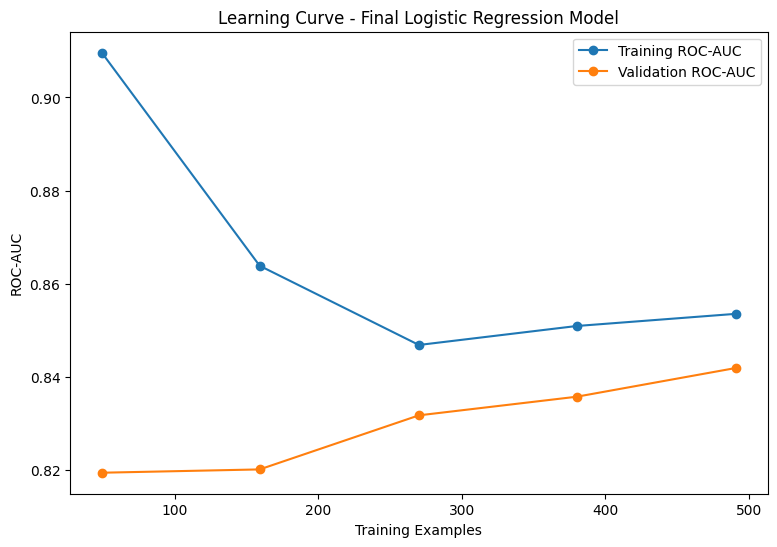

In [ ]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, validation_scores = learning_curve(
    final_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

plt.figure(figsize=(9, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training ROC-AUC"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation ROC-AUC"
)

plt.title("Learning Curve - Final Logistic Regression Model")
plt.xlabel("Training Examples")
plt.ylabel("ROC-AUC")
plt.legend()
plt.show()

In [ ]:
sample_patient = {
    "Pregnancies": 2,
    "Glucose": 130,
    "BloodPressure": 72,
    "SkinThickness": 25,
    "Insulin": 100,
    "BMI": 32.0,
    "DiabetesPedigreeFunction": 0.5,
    "Age": 35
}

result = screen_patient(sample_patient)
result

{'Diabetes_Risk_Probability': np.float64(0.5221226965808636),
 'Prediction': 1,
 'Result': 'Higher Risk - Further Screening Recommended'}

In [ ]:
print("Features used for training:")
print(list(X_train.columns))

print("\nSelected threshold:")
print(best_threshold)

Features used for training:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Obesity_Flag', 'High_Glucose_Flag', 'Age_BMI_Interaction']

Selected threshold:
0.34999999999999987


In [ ]:

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(
    X_train_scaled,
    y_train
)

joblib.dump(
    logistic_model,
    "Diabetes_Disease_prediction.pkl"
)

joblib.dump(
    scaler,
    "scaler.pkl"
)

joblib.dump(
    X.columns.tolist(),
    "columns.pkl"
)

print("Model saved successfully!")
print("Number of features:", len(X.columns))
print("Features:", X.columns.tolist())

Model saved successfully!
Number of features: 11
Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Obesity_Flag', 'High_Glucose_Flag', 'Age_BMI_Interaction']


In [ ]:
joblib.dump(models["Logistic Regression"], "Diabetes_Disease_prediction.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(X.columns.tolist(), "columns.pkl")

['columns.pkl']